In [1]:
from typing import Dict, TypedDict
from langgraph.graph import StateGraph, START, END

In [2]:
class AgentState(TypedDict):
  number1: int
  operator: str
  number2: int
  final: int

In [13]:
def adder(state: AgentState)-> AgentState:
  """ Simple Function to add two numbers """
  state["final"] = state["number1"]+state["number2"]
  return state

def subtractor(state: AgentState) -> AgentState:
  """ Simple Function to subtract two numbers """
  state["final"] = state["number1"] - state["number2"]
  return state

def decide_next_node(state: AgentState) -> AgentState:
  """ Simple function which decides which node to execute next """
  if state["operator"] == "sum":
    return "to_addition_node"
  else:
    return "to_subtraction_node"

 


In [19]:
graph = StateGraph(AgentState)
graph.add_node("addition_node", adder)
graph.add_node("subtraction_node", subtractor)
graph.add_node("decider_node", lambda state:state)

graph.add_edge(START, "decider_node")
graph.add_conditional_edges(
  "decider_node",
  decide_next_node,
  {
    "to_addition_node": "addition_node",
    "to_subtraction_node":"subtraction_node"
  }
)

graph.add_edge("addition_node", END)
graph.add_edge("subtraction_node", END)

app = graph.compile()

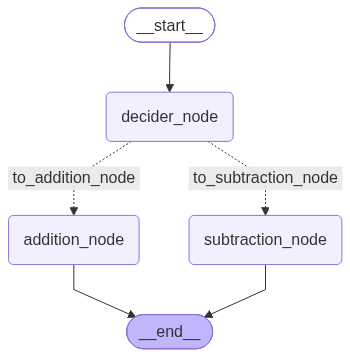

In [20]:
from IPython.display import display, Image
display(Image(app.get_graph().draw_mermaid_png()))

In [22]:
results =  app.invoke({"number1": 10, "operator": "sub", "number2": 5})
print(results)
print(results["final"])

{'number1': 10, 'operator': 'sub', 'number2': 5, 'final': 5}
5
